## 14 Direction, Time, and Mode Concentration (Flag 14)

### Dataset Overview
A constructed WorldTrace case with 100 trajectories. Route geometries come from observed NYC WorldTrace records and retain map-matched coordinates and OSM way identifiers. User, visit sequence, time, mode, vehicle, and weather context are arranged to realize the stated analysis goal.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify the directional, temporal, and mode patterns in the user's trajectories.

Role: Urban mobility analyst


Category: Directional concentration and mode preference

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; the supporting timestamped trajectory-point table is loaded into `user_df`.

In [ ]:
dataset_path = 'trajectories.csv'
df = pd.read_csv(dataset_path)
df['departure_time'] = pd.to_datetime(df['departure_time'])
df['arrival_time'] = pd.to_datetime(df['arrival_time'])

In [ ]:
user_dataset_path = 'trajectory_points.csv'
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How strongly are the user’s trajectories concentrated among the supplied movement directions?

#### Analysis action

Compare trajectory counts and shares across all direction groups.

                     count  share_percent
movement_direction                       
north↔southwest         73           73.0
south↔north             11           11.0
northwest↔southeast      9            9.0
northeast↔southwest      7            7.0


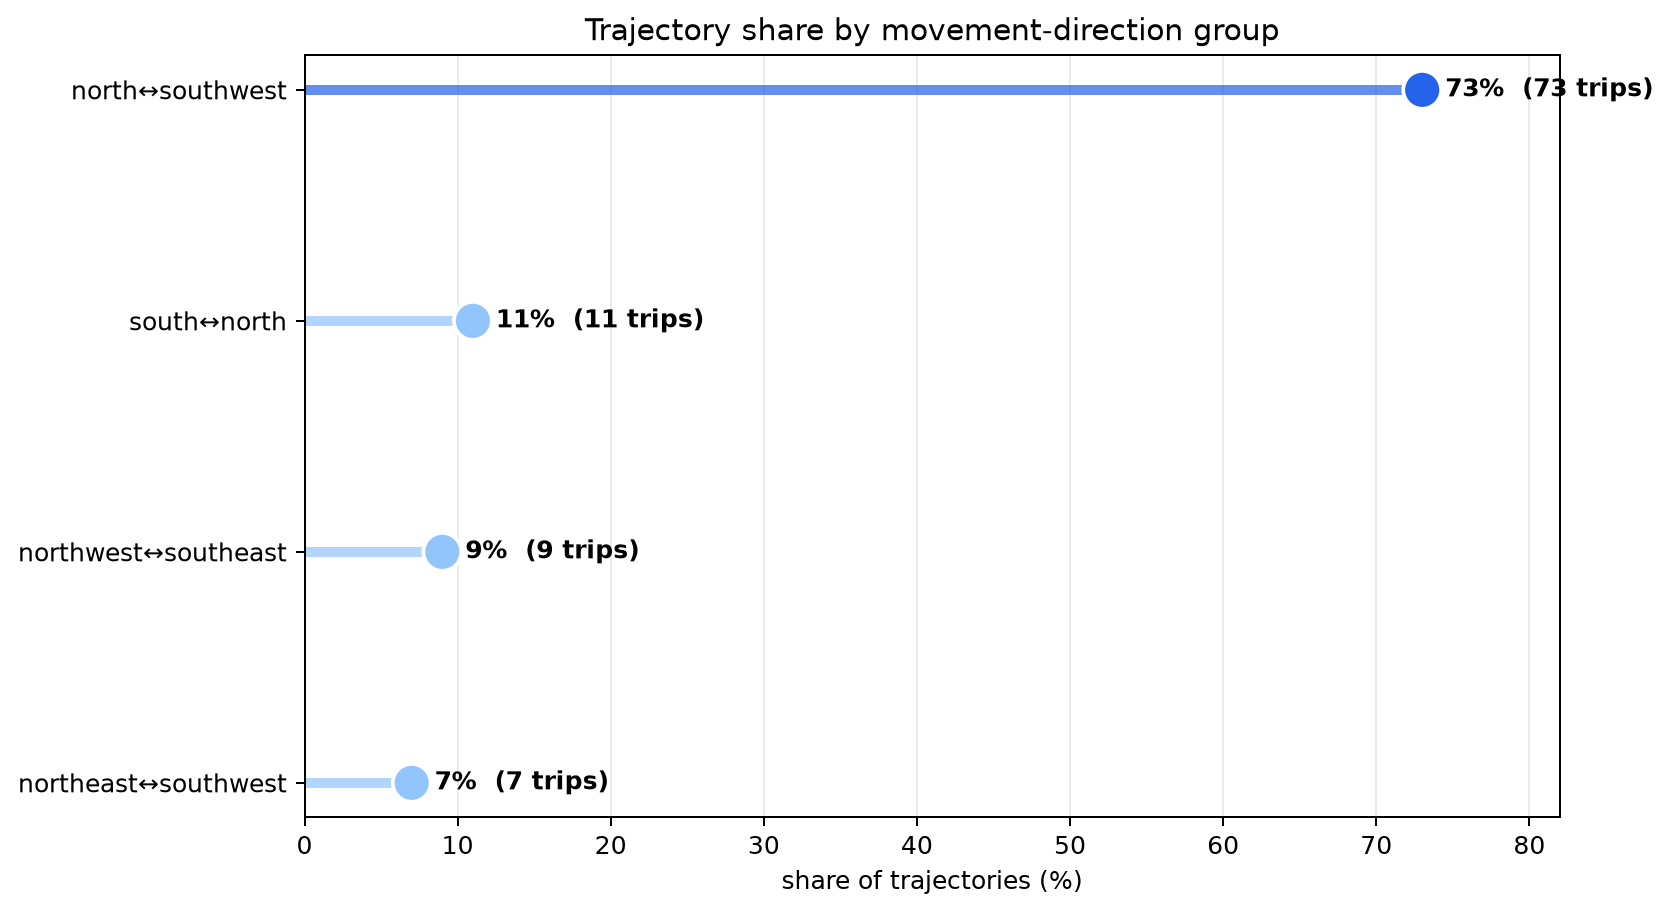

In [1]:
order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest']
counts=df.movement_direction.value_counts().reindex(order,fill_value=0);shares=counts/len(df)*100
print(pd.DataFrame({'count':counts,'share_percent':shares.round(1)}))
fig,ax=plt.subplots(figsize=(9,5.5));y=np.arange(len(order));colors=['#2563eb' if x==shares.max() else '#93c5fd' for x in shares]
ax.hlines(y,0,shares,color=colors,linewidth=4,alpha=.72);ax.scatter(shares,y,s=230,color=colors,edgecolor='white',linewidth=1.5,zorder=3)
ax.set_yticks(y,order);ax.invert_yaxis();ax.set_xlim(0,82);ax.set_xlabel('share of trajectories (%)')
ax.set_title('Trajectory share by movement-direction group');ax.grid(axis='x',alpha=.25)
for yy,value,count in zip(y,shares,counts): ax.text(value+1.5,yy,f'{value:.0f}%  ({count} trips)',va='center',fontweight='bold')
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex14_insight_1",
  "insight": "The user's trajectories are strongly concentrated along a limited set of movement directions rather than being distributed uniformly around the activity space.",
  "plot": {
    "plot_type": "direction_share_lollipop_chart",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Direction, Time, and Mode Concentration: Insight 1",
    "description": "A lollipop chart compares trajectory counts and shares across the supplied movement-direction groups and highlights the dominant group."
  },
  "question": "How strongly are the user’s trajectories concentrated among the supplied movement directions?",
  "actionable_insight": "Compare trajectory counts and shares across all direction groups.",
  "code": "order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest']\ncounts=df.movement_direction.value_counts().reindex(order,fill_value=0);shares=counts/len(df)*100\nprint(pd.DataFrame({'count':counts,'share_percent':shares.round(1)}))\nfig,ax=plt.subplots(figsize=(9,5.5));y=np.arange(len(order));colors=['#2563eb' if x==shares.max() else '#93c5fd' for x in shares]\nax.hlines(y,0,shares,color=colors,linewidth=4,alpha=.72);ax.scatter(shares,y,s=230,color=colors,edgecolor='white',linewidth=1.5,zorder=3)\nax.set_yticks(y,order);ax.invert_yaxis();ax.set_xlim(0,82);ax.set_xlabel('share of trajectories (%)')\nax.set_title('Trajectory share by movement-direction group');ax.grid(axis='x',alpha=.25)\nfor yy,value,count in zip(y,shares,counts): ax.text(value+1.5,yy,f'{value:.0f}%  ({count} trips)',va='center',fontweight='bold')\nplt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 2**: Does the dominant north–southwest direction remain dominant during evening periods across days?

#### Analysis action

Cross-tabulate movement direction by time period and inspect the evening records separately.

Trajectory counts by period
period               morning  midday  evening
movement_direction                           
north↔southwest           45      28        0
south↔north                0       0       11
northwest↔southeast        0       0        9
northeast↔southwest        0       0        7
Within-period shares (%)
period               morning  midday  evening
movement_direction                           
north↔southwest        100.0   100.0      0.0
south↔north              0.0     0.0     40.7
northwest↔southeast      0.0     0.0     33.3
northeast↔southwest      0.0     0.0     25.9
Evening counts by date
date                 04-01  04-02  04-03  04-04  ...  04-18  04-19  04-20  04-21
movement_direction                               ...                            
north↔southwest          0      0      0      0  ...      0      0      0      0
south↔north              0      2      0      0  ...      0      0      1      0
northwest↔southeast      0      0      2      0 

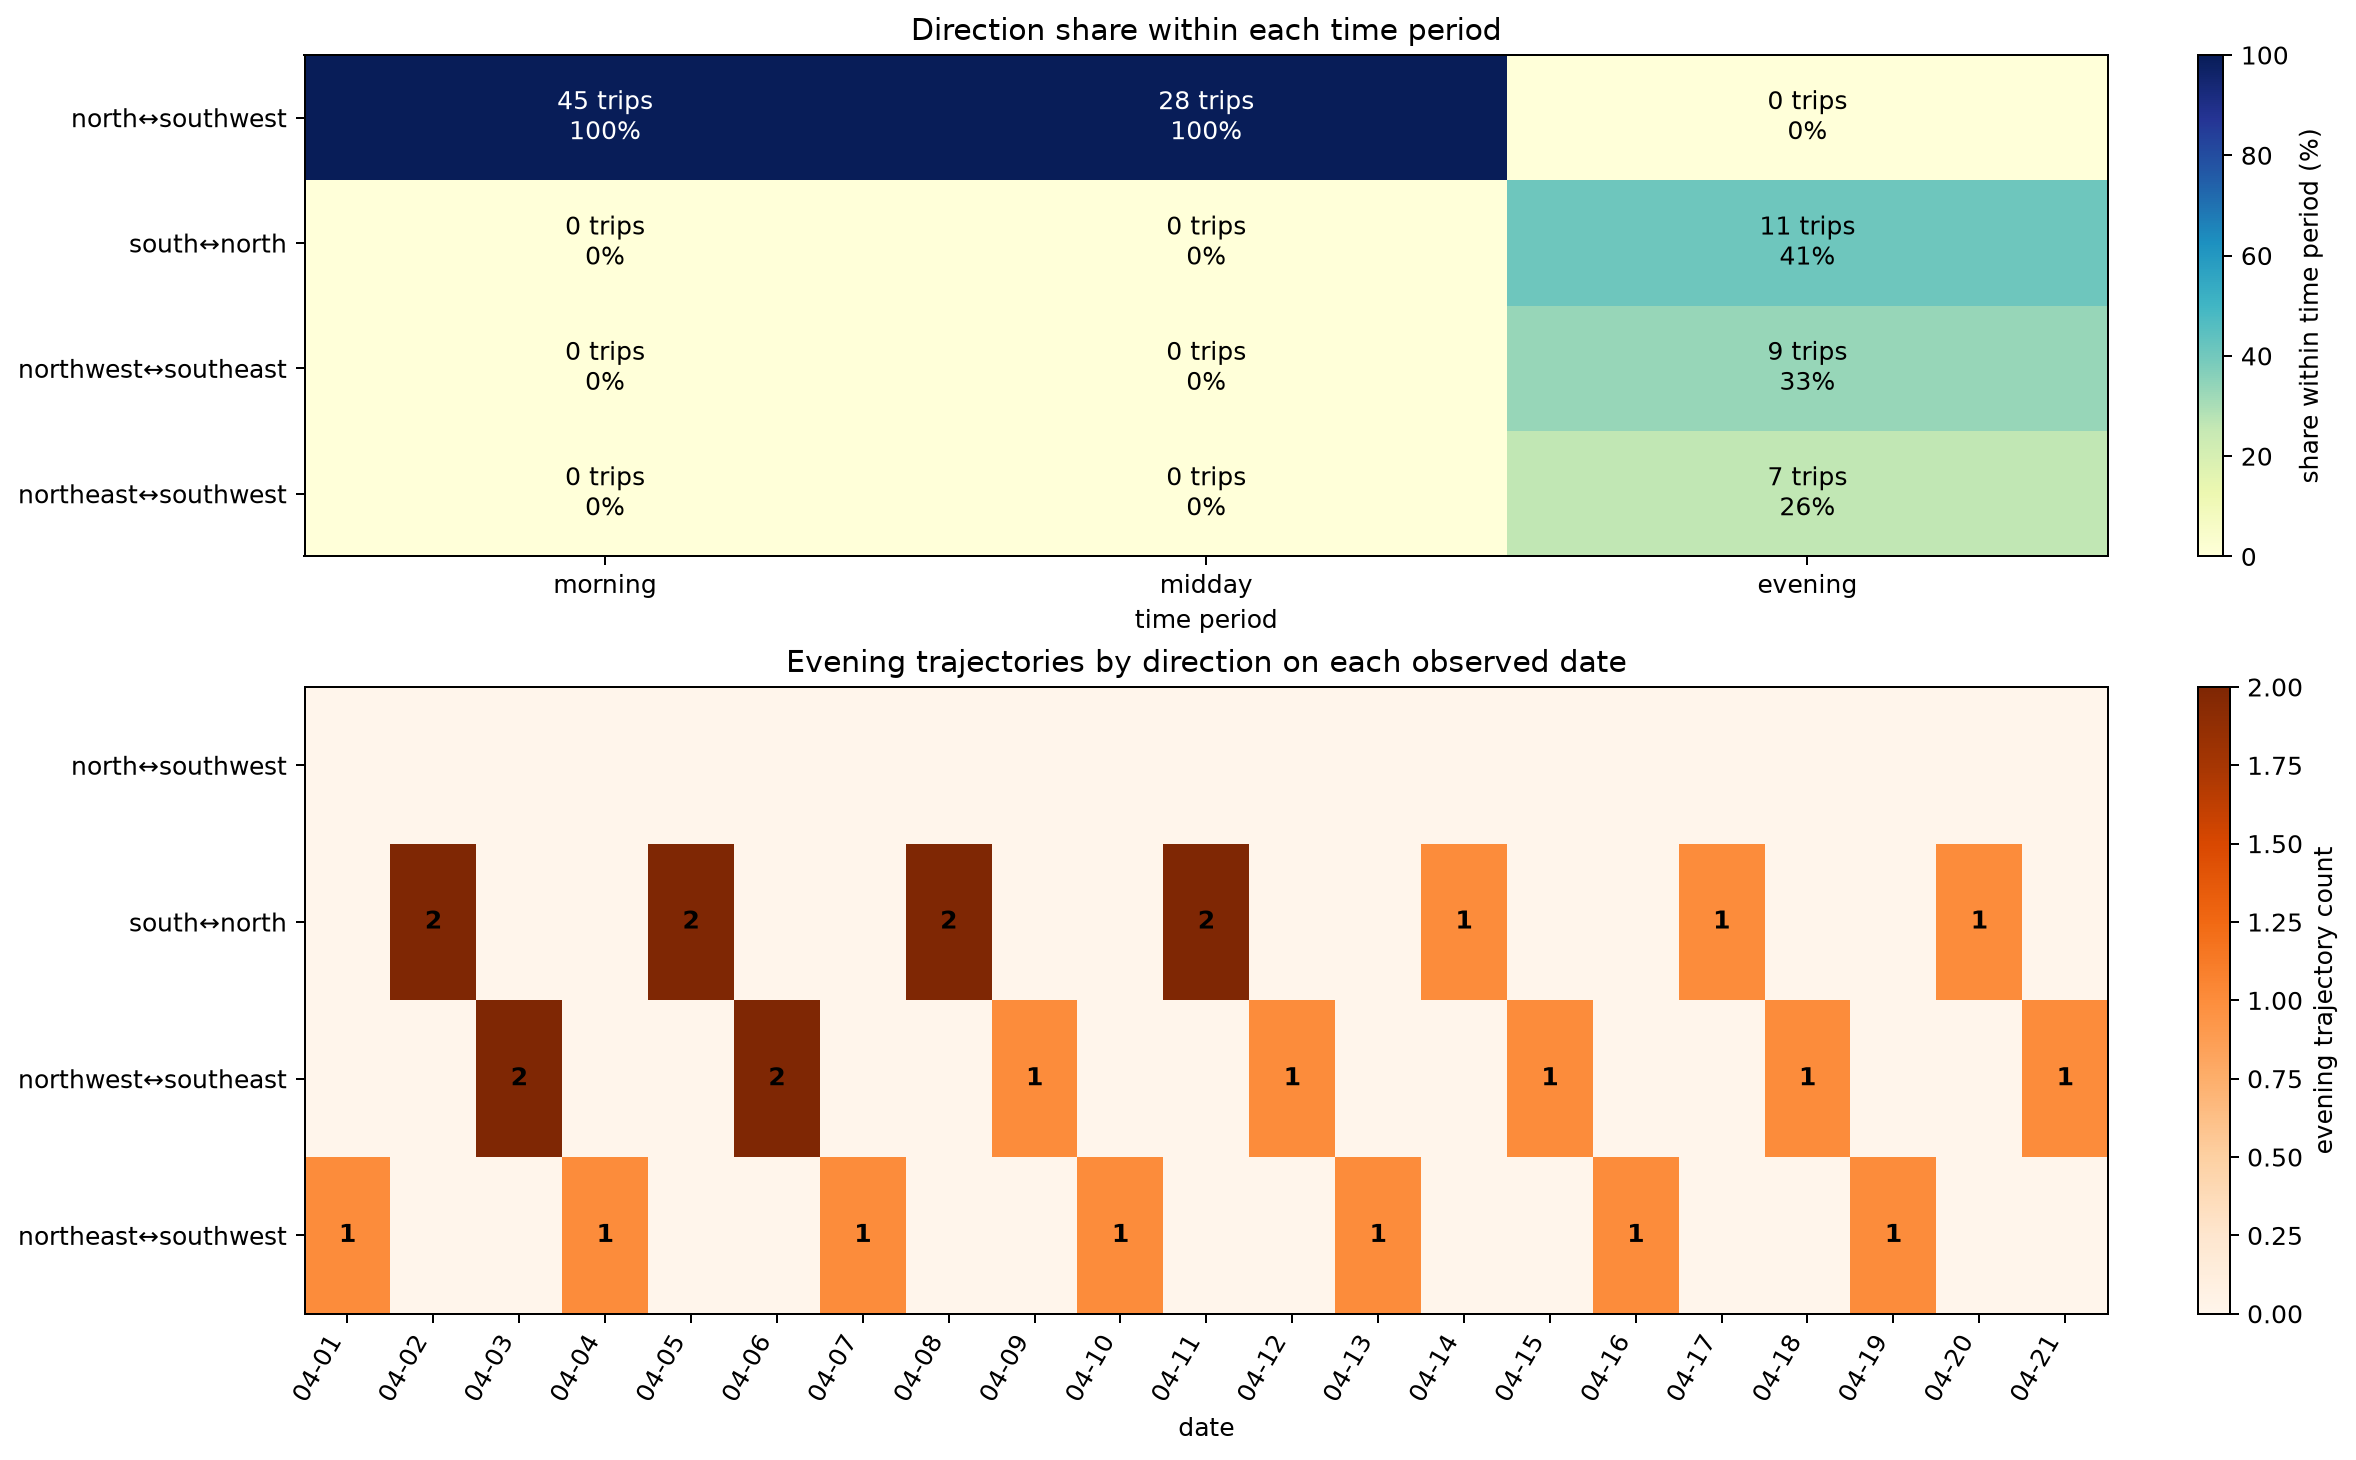

In [2]:
order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest'];periods=['night','morning','midday','evening']
d=df.copy();d['hour']=d.departure_time.dt.hour;d['date']=d.departure_time.dt.strftime('%m-%d');d['period']=pd.cut(d.hour,[-1,5,11,16,23],labels=periods)
tab=pd.crosstab(d.movement_direction,d.period).reindex(index=order,columns=periods,fill_value=0)
tab=tab.loc[:,tab.sum().gt(0)]
share=tab.div(tab.sum(axis=0).replace(0,np.nan),axis=1).mul(100).fillna(0)
evening=d[d.period.eq('evening')];daily=pd.crosstab(evening.movement_direction,evening.date).reindex(index=order,fill_value=0)
print('Trajectory counts by period');print(tab);print('Within-period shares (%)');print(share.round(1));print('Evening counts by date');print(daily)
fig,ax=plt.subplots(2,1,figsize=(13,8),gridspec_kw={'height_ratios':[1,1.25]},constrained_layout=True)
im=ax[0].imshow(share,cmap='YlGnBu',aspect='auto',vmin=0,vmax=100)
ax[0].set_xticks(range(len(share.columns)),share.columns);ax[0].set_yticks(range(len(order)),order)
ax[0].set_xlabel('time period');ax[0].set_title('Direction share within each time period')
for row in range(len(order)):
    for col in range(len(share.columns)):
        value=share.iloc[row,col];ax[0].text(col,row,f'{tab.iloc[row,col]} trips\n{value:.0f}%',ha='center',va='center',color='white' if value>55 else 'black')
im2=ax[1].imshow(daily,cmap='Oranges',aspect='auto',vmin=0,vmax=max(2,daily.to_numpy().max()))
ax[1].set_xticks(range(len(daily.columns)),daily.columns,rotation=60,ha='right');ax[1].set_yticks(range(len(order)),order)
ax[1].set_xlabel('date');ax[1].set_title('Evening trajectories by direction on each observed date')
for row in range(len(order)):
    for col in range(len(daily.columns)):
        value=daily.iloc[row,col]
        if value: ax[1].text(col,row,str(value),ha='center',va='center',fontweight='bold')
fig.colorbar(im,ax=ax[0],label='share within time period (%)');fig.colorbar(im2,ax=ax[1],label='evening trajectory count');plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex14_insight_2",
  "insight": "The concentrated movement directions are not dominant in evening times across different days.",
  "plot": {
    "plot_type": "time_and_daily_evening_direction_heatmaps",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Direction, Time, and Mode Concentration: Insight 2",
    "description": "The upper heatmap compares directions across time periods; the lower heatmap shows the non-dominant directions observed during evening periods on each date."
  },
  "question": "Does the dominant north–southwest direction remain dominant during evening periods across days?",
  "actionable_insight": "Cross-tabulate movement direction by time period and inspect the evening records separately.",
  "code": "order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest'];periods=['night','morning','midday','evening']\nd=df.copy();d['hour']=d.departure_time.dt.hour;d['date']=d.departure_time.dt.strftime('%m-%d');d['period']=pd.cut(d.hour,[-1,5,11,16,23],labels=periods)\ntab=pd.crosstab(d.movement_direction,d.period).reindex(index=order,columns=periods,fill_value=0)\ntab=tab.loc[:,tab.sum().gt(0)]\nshare=tab.div(tab.sum(axis=0).replace(0,np.nan),axis=1).mul(100).fillna(0)\nevening=d[d.period.eq('evening')];daily=pd.crosstab(evening.movement_direction,evening.date).reindex(index=order,fill_value=0)\nprint('Trajectory counts by period');print(tab);print('Within-period shares (%)');print(share.round(1));print('Evening counts by date');print(daily)\nfig,ax=plt.subplots(2,1,figsize=(13,8),gridspec_kw={'height_ratios':[1,1.25]},constrained_layout=True)\nim=ax[0].imshow(share,cmap='YlGnBu',aspect='auto',vmin=0,vmax=100)\nax[0].set_xticks(range(len(share.columns)),share.columns);ax[0].set_yticks(range(len(order)),order)\nax[0].set_xlabel('time period');ax[0].set_title('Direction share within each time period')\nfor row in range(len(order)):\n    for col in range(len(share.columns)):\n        value=share.iloc[row,col];ax[0].text(col,row,f'{tab.iloc[row,col]} trips\\n{value:.0f}%',ha='center',va='center',color='white' if value>55 else 'black')\nim2=ax[1].imshow(daily,cmap='Oranges',aspect='auto',vmin=0,vmax=max(2,daily.to_numpy().max()))\nax[1].set_xticks(range(len(daily.columns)),daily.columns,rotation=60,ha='right');ax[1].set_yticks(range(len(order)),order)\nax[1].set_xlabel('date');ax[1].set_title('Evening trajectories by direction on each observed date')\nfor row in range(len(order)):\n    for col in range(len(daily.columns)):\n        value=daily.iloc[row,col]\n        if value: ax[1].text(col,row,str(value),ha='center',va='center',fontweight='bold')\nfig.colorbar(im,ax=ax[0],label='share within time period (%)');fig.colorbar(im2,ax=ax[1],label='evening trajectory count');plt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 3**: How do travel-mode preference and mean speed differ between the concentrated direction and the other directions?

#### Analysis action

Compare within-direction travel-mode shares together with direction-level mean speed.

 movement_direction travel_mode  trips  mean_speed  share_percent
northeast↔southwest     cycling      4   15.782500      57.142857
northeast↔southwest     driving      2   34.685000      28.571429
northeast↔southwest     walking      1    3.140000      14.285714
northwest↔southeast     cycling      4   16.085000      44.444444
northwest↔southeast     driving      4   35.650000      44.444444
northwest↔southeast     walking      1    4.520000      11.111111
    north↔southwest     driving     65   34.366154      89.041096
    north↔southwest     cycling      8   15.703750      10.958904
        south↔north     cycling      5   16.526000      45.454545
        south↔north     walking      5    5.170000      45.454545
        south↔north     driving      1   33.300000       9.090909
Direction-level mean speed
movement_direction
north↔southwest        32.3
south↔north            12.9
northwest↔southeast    23.5
northeast↔southwest    19.4
Name: mean_speed_kmh, dtype: float64


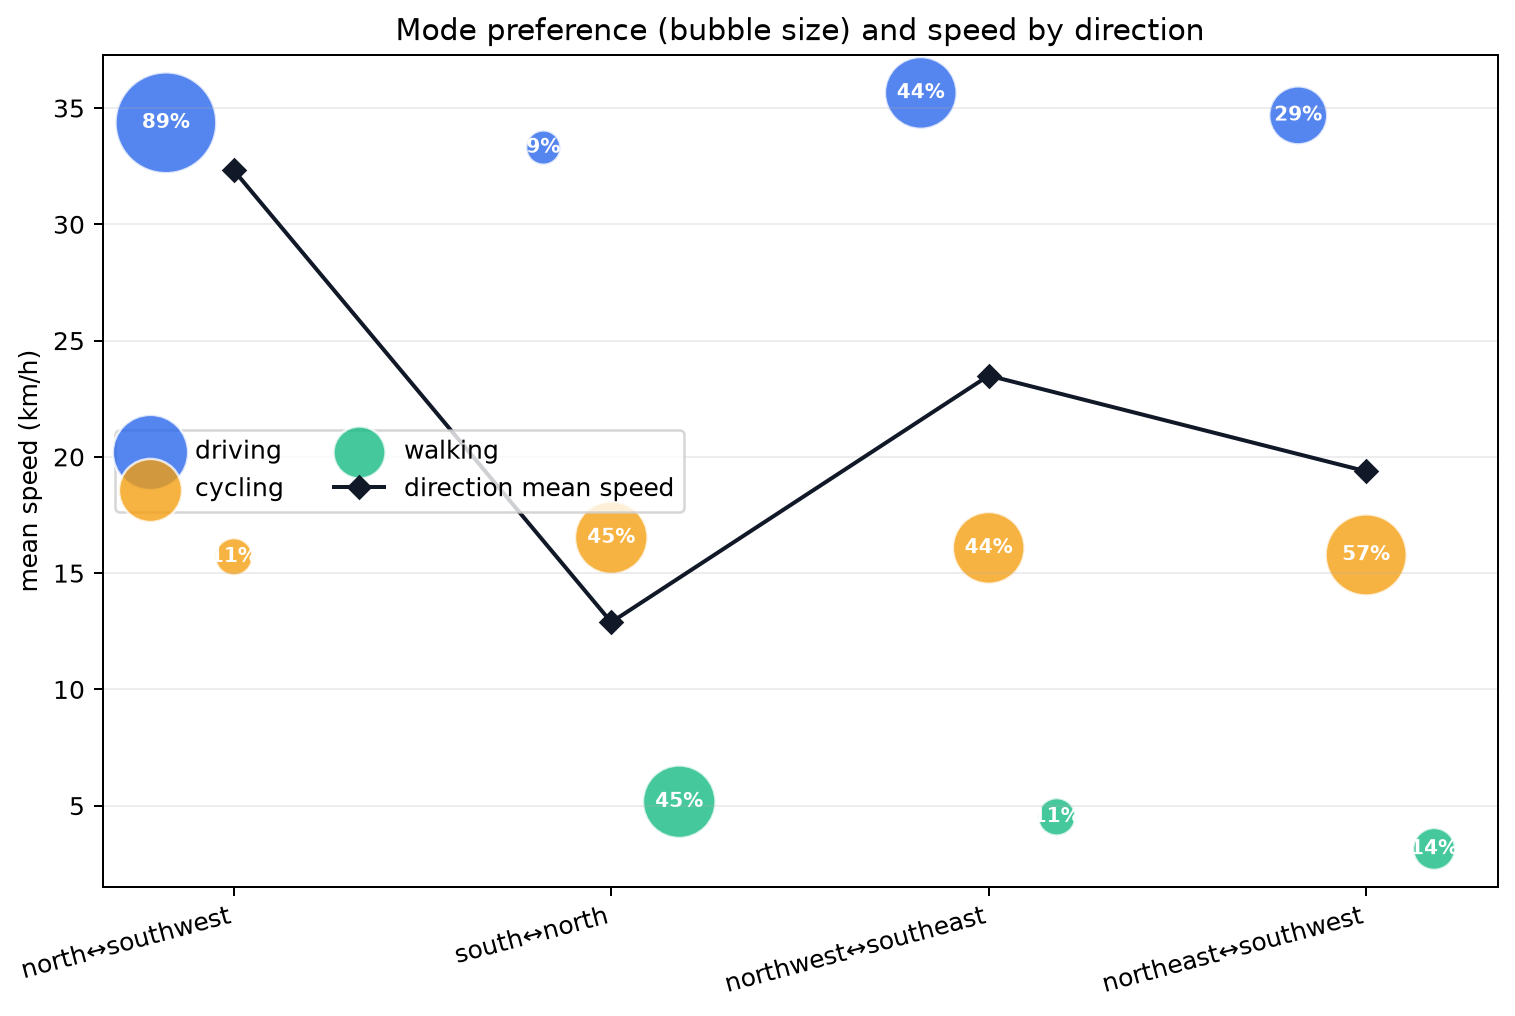

In [3]:
order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest'];modes=['driving','cycling','walking']
g=df.groupby(['movement_direction','travel_mode']).agg(trips=('trajectory_id','size'),mean_speed=('mean_speed_kmh','mean')).reset_index()
totals=g.groupby('movement_direction').trips.transform('sum');g['share_percent']=g.trips/totals*100
direction_speed=df.groupby('movement_direction').mean_speed_kmh.mean().reindex(order)
print(g.sort_values(['movement_direction','share_percent'],ascending=[True,False]).to_string(index=False));print('Direction-level mean speed');print(direction_speed.round(1))
fig,ax=plt.subplots(figsize=(10,6));palette={'driving':'#2563eb','cycling':'#f59e0b','walking':'#10b981'};offset={'driving':-.18,'cycling':0,'walking':.18}
for mode in modes:
    q=g[g.travel_mode.eq(mode)].set_index('movement_direction').reindex(order);x=np.arange(len(order))+offset[mode]
    ax.scatter(x,q.mean_speed,s=q.share_percent.fillna(0)*18+25,color=palette[mode],alpha=.78,edgecolor='white',linewidth=1,label=mode)
    for xx,speed,share in zip(x,q.mean_speed,q.share_percent):
        if pd.notna(speed): ax.text(xx,speed,f'{share:.0f}%',ha='center',va='center',fontsize=8,color='white',fontweight='bold')
ax.plot(np.arange(len(order)),direction_speed,color='#111827',marker='D',linewidth=1.6,label='direction mean speed')
ax.set_xticks(range(len(order)),order,rotation=15,ha='right');ax.set_ylabel('mean speed (km/h)')
ax.set_title('Mode preference (bubble size) and speed by direction');ax.legend(ncol=2);ax.grid(axis='y',alpha=.22);plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex14_insight_3",
  "insight": "The user shows preference of driving rather than walking or cycling for the concentrated movement directions while other routes are used less frequently, and a higher mean speed can be observed in the concentrated route.",
  "plot": {
    "plot_type": "mode_share_speed_bubble_chart",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Direction, Time, and Mode Concentration: Insight 3",
    "description": "Bubble size represents travel-mode share, vertical position represents mode-specific mean speed, and the overlaid line gives direction-level mean speed."
  },
  "question": "How do travel-mode preference and mean speed differ between the concentrated direction and the other directions?",
  "actionable_insight": "Compare within-direction travel-mode shares together with direction-level mean speed.",
  "code": "order=['north↔southwest','south↔north','northwest↔southeast','northeast↔southwest'];modes=['driving','cycling','walking']\ng=df.groupby(['movement_direction','travel_mode']).agg(trips=('trajectory_id','size'),mean_speed=('mean_speed_kmh','mean')).reset_index()\ntotals=g.groupby('movement_direction').trips.transform('sum');g['share_percent']=g.trips/totals*100\ndirection_speed=df.groupby('movement_direction').mean_speed_kmh.mean().reindex(order)\nprint(g.sort_values(['movement_direction','share_percent'],ascending=[True,False]).to_string(index=False));print('Direction-level mean speed');print(direction_speed.round(1))\nfig,ax=plt.subplots(figsize=(10,6));palette={'driving':'#2563eb','cycling':'#f59e0b','walking':'#10b981'};offset={'driving':-.18,'cycling':0,'walking':.18}\nfor mode in modes:\n    q=g[g.travel_mode.eq(mode)].set_index('movement_direction').reindex(order);x=np.arange(len(order))+offset[mode]\n    ax.scatter(x,q.mean_speed,s=q.share_percent.fillna(0)*18+25,color=palette[mode],alpha=.78,edgecolor='white',linewidth=1,label=mode)\n    for xx,speed,share in zip(x,q.mean_speed,q.share_percent):\n        if pd.notna(speed): ax.text(xx,speed,f'{share:.0f}%',ha='center',va='center',fontsize=8,color='white',fontweight='bold')\nax.plot(np.arange(len(order)),direction_speed,color='#111827',marker='D',linewidth=1.6,label='direction mean speed')\nax.set_xticks(range(len(order)),order,rotation=15,ha='right');ax.set_ylabel('mean speed (km/h)')\nax.set_title('Mode preference (bubble size) and speed by direction');ax.legend(ncol=2);ax.grid(axis='y',alpha=.22);plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "transport_mode",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 14)

The user's trajectories are strongly concentrated along a limited set of movement directions rather than being distributed uniformly around the activity space. The concentrated movement directions are not dominant in evening times across different days. The user shows preference of driving rather than walking or cycling for the concentrated movement directions while other routes are used less frequently, and a higher mean speed can be observed in the concentrated route.